Gambler's Problem â€” Value Iteration
-----------------------------------
Goal: $100
Probability of heads: 0.4
Convergence threshold: 1e-12
Value-iteration sweeps: 22

Capital | Probability of winning | Selected optimal stake
--------|------------------------|-----------------------
      1 |             0.00206562 |                     1
      2 |             0.00516406 |                     2
      3 |             0.00922547 |                     3
      4 |             0.01291015 |                     4
      5 |             0.01738540 |                     5
      6 |             0.02306368 |                     6
      7 |             0.02781411 |                     7
      8 |             0.03227539 |                     8
      9 |             0.03768507 |                     9
     10 |             0.04346350 |                    10
     11 |             0.05035447 |                    11
     12 |             0.05765919 |                    12
     13 |             0.06523937

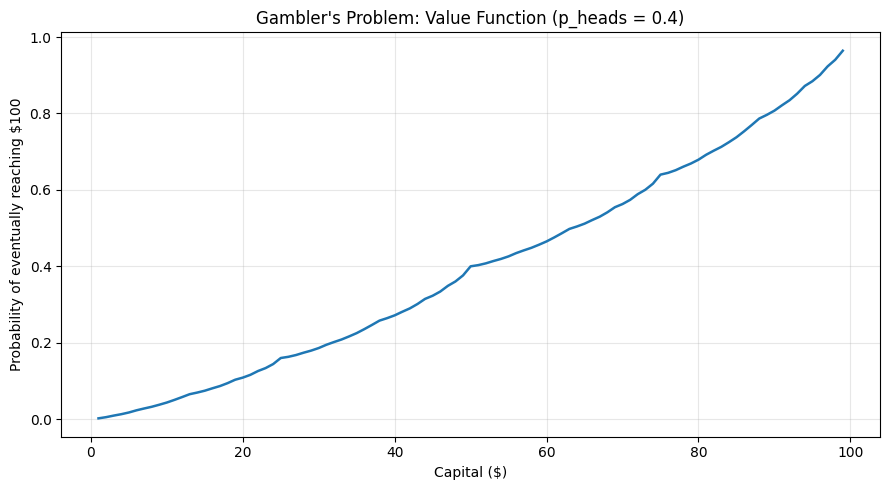

Saved plot to gamblers_optimal_policy.png


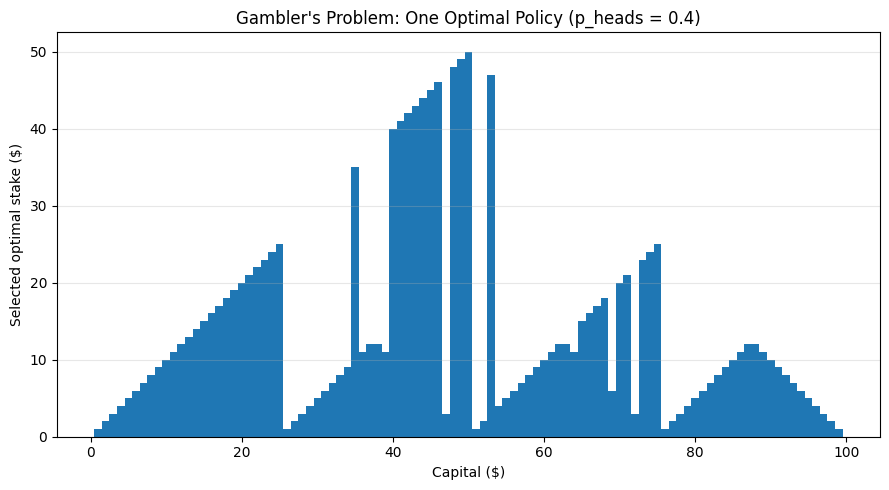

In [1]:
"""
Gambler's Problem using Value Iteration
---------------------------------------
Run:
    python gamblers_problem.py

Requirements:
    pip install numpy matplotlib

The program computes the optimal value function and one optimal policy
for a gambler who wants to reach $100, with P(heads) = 0.4.
"""

import numpy as np
import matplotlib.pyplot as plt


def value_iteration(goal=100, p_heads=0.4, theta=1e-12):
    """
    Returns:
        V: value function, where V[s] is the probability of eventually
           reaching `goal` from capital s under an optimal policy.
        policy: one optimal stake for each capital s.
        sweeps: number of value-iteration sweeps performed.
    """
    if not 0.0 < p_heads < 1.0:
        raise ValueError("p_heads must be between 0 and 1.")

    # V[0] = 0 (bankrupt); V[goal] = 1 (goal reached).
    V = np.zeros(goal + 1, dtype=float)
    V[goal] = 1.0

    sweeps = 0
    while True:
        delta = 0.0
        sweeps += 1

        # In-place updates, as in the textbook's value-iteration pseudocode.
        for capital in range(1, goal):
            old_value = V[capital]
            max_stake = min(capital, goal - capital)

            action_values = []
            for stake in range(1, max_stake + 1):
                value = (
                    p_heads * V[capital + stake]
                    + (1.0 - p_heads) * V[capital - stake]
                )
                action_values.append(value)

            V[capital] = max(action_values)
            delta = max(delta, abs(old_value - V[capital]))

        if delta < theta:
            break

    # Extract one greedy optimal policy from the converged value function.
    policy = np.zeros(goal + 1, dtype=int)
    for capital in range(1, goal):
        max_stake = min(capital, goal - capital)
        action_values = np.array([
            p_heads * V[capital + stake]
            + (1.0 - p_heads) * V[capital - stake]
            for stake in range(1, max_stake + 1)
        ])

        # np.argmax selects the first maximizing stake if there is a tie.
        policy[capital] = int(np.argmax(action_values)) + 1

    return V, policy, sweeps


def main():
    goal = 100
    p_heads = 0.4
    theta = 1e-12

    V, policy, sweeps = value_iteration(goal, p_heads, theta)

    print("Gambler's Problem â€” Value Iteration")
    print("-----------------------------------")
    print(f"Goal: ${goal}")
    print(f"Probability of heads: {p_heads}")
    print(f"Convergence threshold: {theta}")
    print(f"Value-iteration sweeps: {sweeps}")
    print()
    print("Capital | Probability of winning | Selected optimal stake")
    print("--------|------------------------|-----------------------")

    for capital in range(1, goal):
        print(f"{capital:7d} | {V[capital]:22.8f} | {policy[capital]:21d}")

    # Save results in a CSV file for further analysis.
    results = np.column_stack((np.arange(goal + 1), V, policy))
    np.savetxt(
        "gamblers_problem_results.csv",
        results,
        delimiter=",",
        header="capital,value_function,optimal_stake",
        comments="",
        fmt=["%d", "%.12f", "%d"],
    )
    print("\nSaved results to gamblers_problem_results.csv")

    # Plot the value function and one optimal policy.
    capitals = np.arange(1, goal)

    plt.figure(figsize=(9, 5))
    plt.plot(capitals, V[1:goal], linewidth=1.8)
    plt.xlabel("Capital ($)")
    plt.ylabel("Probability of eventually reaching $100")
    plt.title("Gambler's Problem: Value Function (p_heads = 0.4)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("gamblers_value_function.png", dpi=150)
    print("Saved plot to gamblers_value_function.png")
    plt.show()

    plt.figure(figsize=(9, 5))
    plt.bar(capitals, policy[1:goal], width=1.0)
    plt.xlabel("Capital ($)")
    plt.ylabel("Selected optimal stake ($)")
    plt.title("Gambler's Problem: One Optimal Policy (p_heads = 0.4)")
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig("gamblers_optimal_policy.png", dpi=150)
    print("Saved plot to gamblers_optimal_policy.png")
    plt.show()


if __name__ == "__main__":
    main()
